# 🚀 VulHunter — Semantic-Only (CodeBERT) — Optimized

Mode `semantic_only`: Fine-tune toàn bộ `microsoft/codebert-base` cho binary vulnerability detection.

**Kaggle 2xT4, Internet ON, FP16 mixed precision.**

### 🌟 Kỹ thuật tối ưu hóa:
1. **Focal Loss** (auto focal_alpha từ EDA): xử lý class imbalance, focus vào hard samples.
2. **Tiered Learning Rate**: Backbone LR `2e-5` | Classification Head LR `1e-4`.
3. **Threshold Tuning**: Tự động tìm ngưỡng F1 tốt nhất trên Validation set.
4. **Early Stopping**: Dừng nếu Val F1 không tăng sau `PATIENCE` epochs.
5. **Dynamic Padding `pad_to_multiple_of=8`**: Tối đa hóa Tensor Cores (T4/A100/V100).
6. **Fused AdamW** (`fused=True`): Kernel-fused optimizer, nhanh hơn ~10% trên GPU.
7. **`cudnn.benchmark=True`**: CuDNN tự tìm conv algorithm tốt nhất.
8. **Cosine LR Schedule** với warmup 10%.
9. **Gradient Checkpointing**: Giảm VRAM ~40% (trade-off tốc độ ~20%).
10. **`set_seed(42)`**: Đảm bảo tính tái lập (reproducibility).

## 1. Setup môi trường

In [1]:
import os
import subprocess
import random
import math
import time
import json
from pathlib import Path

# ── Biến môi trường trước khi import torch ──
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'
os.environ['TOKENIZERS_PARALLELISM'] = 'true'   # Cho phép tokenization song song
os.environ['TRANSFORMERS_VERBOSITY'] = 'error'

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from functools import partial
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (confusion_matrix, roc_auc_score,
                             average_precision_score, precision_recall_curve, roc_curve,
                             classification_report)

# ⚡ Kỹ thuật tối ưu: CuDNN benchmark mode
# Cho phép CuDNN tự động tìm thuật toán conv tốt nhất cho hardware cụ thể
torch.backends.cudnn.benchmark = True

# ⚡ Kỹ thuật tối ưu: Reproducibility seed (aligned với optimized notebook)
try:
    from transformers import set_seed
    set_seed(42)
except ImportError:
    random.seed(42)
    np.random.seed(42)
    torch.manual_seed(42)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(42)

sns.set_theme(style='whitegrid', context='notebook')
IS_KAGGLE = Path('/kaggle').exists()
print(f'IS_KAGGLE = {IS_KAGGLE}, PyTorch = {torch.__version__}')

num_gpus = torch.cuda.device_count()
print(f'✅ Số lượng GPU khả dụng: {num_gpus}')
for i in range(num_gpus):
    props = torch.cuda.get_device_properties(i)
    print(f'   - GPU {i}: {props.name} | VRAM: {props.total_memory / 1e9:.2f} GB')

# Clone VulHunter repo từ GitHub (nếu chạy trên Kaggle)
GITHUB_REPO = 'https://github.com/NhatWoan-20/VulHunter.git'
REPO_DIR = Path('/kaggle/working/VulHunter') if IS_KAGGLE else Path.cwd()

if IS_KAGGLE and not REPO_DIR.exists():
    print(f'Cloning VulHunter from GitHub to {REPO_DIR}...')
    result = subprocess.run(['git', 'clone', GITHUB_REPO, str(REPO_DIR)],
                            capture_output=True, text=True)
    if result.returncode != 0:
        print(f'Clone failed: {result.stderr}')
        raise RuntimeError('Failed to clone VulHunter repo')
    print('Clone successful!')
    print('Installing dependencies...')
    subprocess.run(['pip', 'install', '-e', str(REPO_DIR), '-q'], capture_output=True)

import sys
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))
print(f'Using repo: {REPO_DIR}')

# Test imports
import importlib
errors = []
modules_to_test = [
    'src.multitask.model',
    'src.utils.dataset',
    'src.utils.losses',
    'src.utils.metrics',
    'src.semantic.encoder',
]
for mod_name in modules_to_test:
    try:
        importlib.import_module(mod_name)
    except Exception as e:
        errors.append((mod_name, e))

if errors:
    for mod, e in errors:
        print(f'  ❌ {mod}: {e}')
    raise ImportError('Modules failed — xem lỗi trên')

from src.multitask.model import VulHunterModel, ModelOutput
from src.utils.dataset import VulHunterDataset, collate_fn
from src.utils.losses import BinaryClassificationLoss
from src.utils.metrics import binary_metrics, find_best_threshold
print('✅ All imports OK')

IS_KAGGLE = True, PyTorch = 2.11.0+cu128
✅ Số lượng GPU khả dụng: 2
   - GPU 0: Tesla T4 | VRAM: 15.64 GB
   - GPU 1: Tesla T4 | VRAM: 15.64 GB
Cloning VulHunter from GitHub to /kaggle/working/VulHunter...
Clone successful!
Installing dependencies...
Using repo: /kaggle/working/VulHunter
✅ All imports OK


## 2. Đường dẫn dữ liệu + EDA (tự động tính focal_alpha)

In [2]:
if IS_KAGGLE:
    DATA_DIR = Path("/kaggle/input/datasets/ngnhat19/vulhunter-raw-data")
else:
    DATA_DIR = REPO_DIR / "data" / "splits"
TRAIN_JSONL = DATA_DIR / "train.jsonl"
VAL_JSONL   = DATA_DIR / "validation.jsonl"
TEST_JSONL  = DATA_DIR / "test.jsonl"
print(f"Train={TRAIN_JSONL.exists()}, Val={VAL_JSONL.exists()}, Test={TEST_JSONL.exists()}")

def quick_eda(path, n=100000):
    """Đọc n samples đầu tiên để tính class distribution và auto focal_alpha."""
    rows = []
    with path.open() as f:
        for i, line in enumerate(f):
            if i >= n: break
            r = json.loads(line)
            rows.append({"binary_label": r.get("binary_label")})

    df = pd.DataFrame(rows)
    print(f"\nLoaded {len(df)} samples")
    print(f"Binary:\n{df['binary_label'].value_counts(normalize=True).round(3)}")

    pos_rate = df['binary_label'].mean()
    # focal_alpha = tỷ lệ class negative (để balance loss cho positive class hiếm hơn)
    # Aligned với codebert_finetune_optimized: focal_alpha = 1 - pos_rate
    return df, 1 - pos_rate

eda_df, AUTO_FOCAL_ALPHA = quick_eda(TRAIN_JSONL)
print(f"\n🎯 Auto focal_alpha = {AUTO_FOCAL_ALPHA:.3f}")

Train=True, Val=True, Test=True

Loaded 100000 samples
Binary:
binary_label
0    0.784
1    0.216
Name: proportion, dtype: float64

🎯 Auto focal_alpha = 0.784


## 3. Cấu hình Hyperparameters (Optimized — aligned với codebert_finetune_optimized.ipynb)

In [3]:
MODE = "semantic_only"
MAX_LEN = 512

# ⚡ Batch size: optimized notebook dùng 32/GPU
# Nếu chạy 2x T4 (16GB mỗi cái), 32 samples/GPU là hợp lý
# Với custom training loop, dùng GRAD_ACCUM để mô phỏng large batch
BATCH_SIZE = 32               # per GPU — aligned với optimized notebook (32/GPU)
GRAD_ACCUM = 1                # effective batch = BATCH_SIZE * GRAD_ACCUM * num_gpus

# ⚡ Kỹ thuật 4: Tăng EPOCHS để Early Stopping có đủ room hoạt động
EPOCHS = 15                   # aligned với optimized notebook

# ⚡ Kỹ thuật 2: Tiered Learning Rate
LR_BACKBONE = 2.0e-5          # LR nhỏ cho backbone CodeBERT (đã pre-trained)
LR_HEAD = 1.0e-4              # LR lớn cho classification head (mới khởi tạo)
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.1            # 10% của tổng steps cho warmup

# ⚡ Kỹ thuật 1: Focal Loss params
FOCAL_ALPHA = AUTO_FOCAL_ALPHA  # auto-computed từ EDA
FOCAL_GAMMA = 2.0

# ⚡ Kỹ thuật 4: Early Stopping
PATIENCE = 3                  # aligned với optimized notebook (patience=3)

NUM_WORKERS = 2
USE_AMP = True

# ⚡ Kỹ thuật 3: Threshold Tuning
TUNE_THRESHOLD = True

# Model config — SemanticEncoder params
SEMANTIC_CFG = {
    "encoder_type": "codebert",
    "backbone": "microsoft/codebert-base",
    "output_dim": 256,
    "freeze_layers": 0,         # 0 = full fine-tuning (aligned với optimized notebook)
    "dropout": 0.1,
    "pooling": "last",          # CLS token pooling
    "gradient_checkpointing": False,  # Disable để tăng tốc (đủ VRAM với batch=32)
    "use_fp16": True,           # AMP quản lý externally
}

HEAD_CFG = {"binary": {"hidden_dim": 128, "dropout": 0.3}}
print(f"Mode: {MODE}")
print(f"Effective batch size: {BATCH_SIZE * GRAD_ACCUM} (per GPU) × {max(1, torch.cuda.device_count())} GPUs")
print(f"Focal Loss: alpha={FOCAL_ALPHA:.3f}, gamma={FOCAL_GAMMA}")
print(f"LR: backbone={LR_BACKBONE}, head={LR_HEAD}")

Mode: semantic_only
Effective batch size: 32 (per GPU) × 2 GPUs
Focal Loss: alpha=0.784, gamma=2.0
LR: backbone=2e-05, head=0.0001


## 4. Build Model + Load Datasets

In [4]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

model = VulHunterModel(
    mode=MODE,
    semantic_config=SEMANTIC_CFG,
    head_config=HEAD_CFG,
)
model.to(device)

# DataParallel nếu có nhiều GPU (aligned với optimized notebook 2x T4)
if torch.cuda.device_count() > 1:
    model = nn.DataParallel(model)
    print(f"⚡ Sử dụng DataParallel trên {torch.cuda.device_count()} GPUs")

# Đảm bảo tất cả trainable params ở float32 (cho GradScaler compatibility)
for p in model.parameters():
    if p.requires_grad and p.dtype != torch.float32:
        p.data = p.data.float()

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f"📊 [{MODE}] Trainable: {trainable:,} / {total:,} ({100*trainable/total:.2f}% trainable)")

# ── Datasets và DataLoaders ──
# ⚡ Kỹ thuật 5: pad_to_multiple_of=8 trong collate_fn (aligned với DataCollatorWithPadding)
# Sử dụng functools.partial để truyền pad_to_multiple_of vào collate_fn
collate_fn_padded = partial(collate_fn, pad_to_multiple_of=8)

train_ds = VulHunterDataset(data_path=TRAIN_JSONL, max_length=MAX_LEN, tokenizer_name="microsoft/codebert-base")
val_ds   = VulHunterDataset(data_path=VAL_JSONL,   max_length=MAX_LEN, tokenizer_name="microsoft/codebert-base")
test_ds  = VulHunterDataset(data_path=TEST_JSONL,  max_length=MAX_LEN, tokenizer_name="microsoft/codebert-base")

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True,
    collate_fn=collate_fn_padded, num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE * 2, shuffle=False,
    collate_fn=collate_fn_padded, num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)
test_loader = DataLoader(
    test_ds, batch_size=BATCH_SIZE * 2, shuffle=False,
    collate_fn=collate_fn_padded, num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)
print(f"✅ Train: {len(train_ds):,} | Val: {len(val_ds):,} | Test: {len(test_ds):,}")
print(f"   Batches — Train: {len(train_loader)} | Val: {len(val_loader)} | Test: {len(test_loader)}")

config.json:   0%|          | 0.00/498 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  499MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

⚡ Sử dụng DataParallel trên 2 GPUs
📊 [semantic_only] Trainable: 124,951,041 / 124,951,041 (100.00% trainable)
✅ Train: 111,902 | Val: 13,987 | Test: 13,990
   Batches — Train: 3497 | Val: 219 | Test: 219


## 5. Optimizer + LR Scheduler (Tiered LR + Cosine + Fused AdamW)

In [5]:
# ⚡ Kỹ thuật 1: Focal Loss với auto focal_alpha
criterion = BinaryClassificationLoss(focal_alpha=FOCAL_ALPHA, focal_gamma=FOCAL_GAMMA)

# ⚡ Kỹ thuật 2: Tiered Learning Rate — Backbone LR nhỏ, Head LR lớn
# Aligned với OptimizedTrainer.create_optimizer() trong codebert_finetune_optimized.ipynb
backbone_params, head_params = [], []
base_model = model.module if isinstance(model, nn.DataParallel) else model
for name, p in base_model.named_parameters():
    if not p.requires_grad:
        continue
    if "semantic_encoder.backbone" in name:
        backbone_params.append(p)
    else:
        head_params.append(p)

param_groups = []
if backbone_params:
    param_groups.append({"params": backbone_params, "lr": LR_BACKBONE, "weight_decay": WEIGHT_DECAY})
if head_params:
    param_groups.append({"params": head_params, "lr": LR_HEAD, "weight_decay": WEIGHT_DECAY})

# ⚡ Kỹ thuật 6: Fused AdamW (kernel-fused, nhanh hơn ~10% trên GPU)
# Tương đương optim="adamw_torch_fused" trong HF TrainingArguments
# Requires PyTorch >= 2.0 và CUDA
use_fused_adamw = (
    torch.cuda.is_available()
    and hasattr(torch.optim, 'AdamW')
    and 'fused' in torch.optim.AdamW.__init__.__code__.co_varnames
)
if use_fused_adamw:
    optimizer = torch.optim.AdamW(param_groups, fused=True)
    print(f"⚡ Sử dụng Fused AdamW (PyTorch {torch.__version__})")
else:
    optimizer = torch.optim.AdamW(param_groups)
    print(f"ℹ️  Dùng AdamW thường (fused không khả dụng, PyTorch {torch.__version__})")

# ⚡ Cosine LR Schedule với warmup (aligned với lr_scheduler_type='cosine', warmup_ratio=0.1)
total_steps = len(train_loader) // GRAD_ACCUM * EPOCHS
warmup_steps = int(total_steps * WARMUP_RATIO)

def lr_lambda(current_step: int) -> float:
    """Linear warmup + Cosine decay — aligned với HF cosine scheduler."""
    if current_step < warmup_steps:
        return float(current_step) / float(max(1, warmup_steps))
    progress = float(current_step - warmup_steps) / float(max(1, total_steps - warmup_steps))
    return max(0.0, 0.5 * (1.0 + math.cos(math.pi * min(1.0, progress))))

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP and torch.cuda.is_available())

print(f"Optimizer: {len(backbone_params)} backbone params + {len(head_params)} head params")
print(f"Total steps: {total_steps} | Warmup steps: {warmup_steps} ({WARMUP_RATIO*100:.0f}%)")

⚡ Sử dụng Fused AdamW (PyTorch 2.11.0+cu128)
Optimizer: 199 backbone params + 12 head params
Total steps: 52455 | Warmup steps: 5245 (10%)


## 6. Training Loop + Evaluation Functions

In [12]:
import time
import numpy as np
import torch
from tqdm.auto import tqdm

def train_one_epoch(model, loader, optimizer, scheduler, scaler, epoch):
    """Train một epoch với gradient accumulation, mixed precision và progress bar."""
    model.train()
    total_loss = 0.0
    n = 0
    optimizer.zero_grad(set_to_none=True)
    
    # 🔴 Bọc DataLoader bằng thanh tiến trình tqdm
    pbar = tqdm(loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Train]", leave=False)

    for step, batch in enumerate(pbar):
        kwargs = {
            "input_ids": batch["input_ids"].to(device, non_blocking=True),
            "attention_mask": batch["attention_mask"].to(device, non_blocking=True),
        }
        targets = batch["binary_labels"].to(device, non_blocking=True)
        is_accumulating = ((step + 1) % GRAD_ACCUM != 0) and ((step + 1) != len(loader))

        if USE_AMP and torch.cuda.is_available():
            with torch.autocast(device_type="cuda", dtype=torch.float16):
                out = model(**kwargs)
                
                # Bản vá lỗi DataParallel
                if hasattr(out, 'binary_logits') and type(out.binary_logits) is map:
                    out.binary_logits, out.fused_embedding = tuple(out.binary_logits)
                    
                losses = criterion(
                    binary_logits=out.binary_logits if hasattr(out, 'binary_logits') else out[0],
                    binary_targets=targets,
                )
                loss = losses["total"] / GRAD_ACCUM
            scaler.scale(loss).backward()
        else:
            out = model(**kwargs)
            
            # Bản vá lỗi DataParallel
            if hasattr(out, 'binary_logits') and type(out.binary_logits) is map:
                out.binary_logits, out.fused_embedding = tuple(out.binary_logits)
                
            losses = criterion(
                binary_logits=out.binary_logits if hasattr(out, 'binary_logits') else out[0],
                binary_targets=targets,
            )
            loss = losses["total"] / GRAD_ACCUM
            loss.backward()

        if not is_accumulating:
            if USE_AMP and scaler is not None:
                try:
                    scaler.unscale_(optimizer)
                except ValueError:
                    for p in model.parameters():
                        if p.requires_grad and p.dtype != torch.float32:
                            p.data = p.data.float()
                    try:
                        scaler.unscale_(optimizer)
                    except Exception:
                        pass
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(optimizer)
                scaler.update()
            else:
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
            scheduler.step()
            optimizer.zero_grad(set_to_none=True)

        total_loss += loss.item() * GRAD_ACCUM
        n += 1
        
        # 🔴 Cập nhật loss và learning rate lên đuôi thanh tiến trình
        if (step + 1) % 10 == 0 or step == len(loader) - 1:
            pbar.set_postfix({
                'loss': f"{total_loss/n:.4f}", 
                'lr': f"{optimizer.param_groups[0]['lr']:.2e}"
            })

    return total_loss / max(n, 1)

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss = 0.0
    all_true, all_prob = [], []
    n = 0

    # 🔴 Bọc thanh tiến trình cho tập Validation
    pbar = tqdm(loader, desc="Evaluating", leave=False)

    for batch in pbar:
        kwargs = {
            "input_ids": batch["input_ids"].to(device, non_blocking=True),
            "attention_mask": batch["attention_mask"].to(device, non_blocking=True),
        }
        targets = batch["binary_labels"].to(device, non_blocking=True)
        
        if USE_AMP and torch.cuda.is_available():
            with torch.autocast(device_type="cuda", dtype=torch.float16):
                out = model(**kwargs)
        else:
            out = model(**kwargs)
            
        # Bản vá lỗi DataParallel
        if hasattr(out, 'binary_logits') and type(out.binary_logits) is map:
            out.binary_logits, out.fused_embedding = tuple(out.binary_logits)
            
        binary_logits = out.binary_logits if hasattr(out, 'binary_logits') else out[0]
            
        losses = criterion(
            binary_logits=binary_logits,
            binary_targets=targets,
        )
        total_loss += losses["total"].item()
        n += 1
        
        if binary_logits is not None:
            probs = torch.sigmoid(binary_logits.squeeze(-1))
            all_true.extend(targets.cpu().tolist())
            all_prob.extend(probs.cpu().tolist())

    return np.array(all_true), np.array(all_prob)

print("✅ Training functions defined")

✅ Training functions defined


## 7. Main Training Loop (với Early Stopping + Threshold Tuning)

In [13]:
# ── Checkpoint directory ──
CKPT_DIR = Path("/kaggle/working/models/checkpoints/semantic") if IS_KAGGLE else REPO_DIR / "models/checkpoints/semantic"
CKPT_DIR.mkdir(parents=True, exist_ok=True)

# ── State ──
best_f1 = 0.0
best_threshold = 0.5
patience_counter = 0
history = []

print("🚀 Bắt đầu Full Fine-Tuning CodeBERT (Tất cả kỹ thuật tối ưu đã áp dụng)...")
print(f"   Max epochs: {EPOCHS} | Early stopping patience: {PATIENCE}")
print(f"   Focal Loss: alpha={FOCAL_ALPHA:.3f}, gamma={FOCAL_GAMMA}")
print(f"   Tiered LR: backbone={LR_BACKBONE}, head={LR_HEAD}")
print(f"   pad_to_multiple_of=8, {'Fused AdamW' if use_fused_adamw else 'AdamW'}")

for epoch in range(EPOCHS):
    t0 = time.time()
    train_loss = train_one_epoch(model, train_loader, optimizer, scheduler, scaler, epoch)
    val_y, val_prob = evaluate(model, val_loader)
    elapsed = time.time() - t0

    # ⚡ Kỹ thuật 3: Threshold Tuning — tìm ngưỡng F1 tốt nhất trên Validation set
    if TUNE_THRESHOLD and len(val_y) > 0:
        thr, m = find_best_threshold(val_y, val_prob)
    else:
        thr = 0.5
        preds = (val_prob >= thr).astype(int)
        m = binary_metrics(val_y, preds, val_prob, threshold=thr)

    val_f1 = m.f1
    print(f"\nEpoch {epoch+1}/{EPOCHS} ({elapsed:.1f}s) | "
          f"Train loss={train_loss:.4f} | "
          f"Val F1={val_f1:.4f} | P={m.precision:.4f} | R={m.recall:.4f} | "
          f"AUC={m.auc:.4f} | thr={thr:.2f}")

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_f1": val_f1,
        "val_metrics": m.to_dict(),
        "threshold": thr,
        "elapsed": elapsed,
    })

    # ── Checkpoint tốt nhất ──
    if val_f1 > best_f1:
        best_f1 = val_f1
        best_threshold = thr
        patience_counter = 0

        base_model = model.module if isinstance(model, nn.DataParallel) else model
        trainable_names = {n for n, p in base_model.named_parameters() if p.requires_grad}
        sd = {k: v.cpu() for k, v in base_model.state_dict().items() if k in trainable_names}
        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": sd,
            "best_f1": best_f1,
            "best_threshold": best_threshold,
            "config": {
                "mode": MODE,
                "model": {"semantic": SEMANTIC_CFG, "heads": HEAD_CFG},
                "focal_alpha": FOCAL_ALPHA,
                "focal_gamma": FOCAL_GAMMA,
            },
            "history": history,
        }, CKPT_DIR / "best.pt")
        print(f"  ✅ Saved best (F1={best_f1:.4f}, thr={best_threshold:.2f})")
    else:
        patience_counter += 1
        # ⚡ Kỹ thuật 4: Early Stopping
        if patience_counter >= PATIENCE:
            print(f"\n⏹️ Early stopping sau {PATIENCE} epochs không cải thiện.")
            break

print(f"\n✅ Best Val F1 = {best_f1:.4f} @ threshold {best_threshold:.2f}")
print(f"⏱️  Tổng epochs đã chạy: {len(history)}")

🚀 Bắt đầu Full Fine-Tuning CodeBERT (Tất cả kỹ thuật tối ưu đã áp dụng)...
   Max epochs: 15 | Early stopping patience: 3
   Focal Loss: alpha=0.784, gamma=2.0
   Tiered LR: backbone=2e-05, head=0.0001
   pad_to_multiple_of=8, Fused AdamW


Epoch 1/15 [Train]:   0%|          | 0/3497 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/219 [00:00<?, ?it/s]


Epoch 1/15 (1865.1s) | Train loss=0.0400 | Val F1=0.6707 | P=0.6042 | R=0.7536 | AUC=0.8991 | thr=0.60
  ✅ Saved best (F1=0.6707, thr=0.60)


Epoch 2/15 [Train]:   0%|          | 0/3497 [00:00<?, ?it/s]

...

Evaluating:   0%|          | 0/219 [00:00<?, ?it/s]


Epoch 9/15 (1854.9s) | Train loss=0.0108 | Val F1=0.7428 | P=0.6512 | R=0.8645 | AUC=0.9387 | thr=0.35


Epoch 10/15 [Train]:   0%|          | 0/3497 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/219 [00:00<?, ?it/s]


Epoch 10/15 (1862.3s) | Train loss=0.0094 | Val F1=0.7451 | P=0.6475 | R=0.8774 | AUC=0.9381 | thr=0.25

⏹️ Early stopping sau 3 epochs không cải thiện.

✅ Best Val F1 = 0.7463 @ threshold 0.45
⏱️  Tổng epochs đã chạy: 10


## 8. Đánh giá trên Test Set (với Optimal Threshold)

In [15]:
# Load best checkpoint
ckpt_path = CKPT_DIR / "best.pt"
if ckpt_path.exists():
    ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
    base_model = model.module if isinstance(model, nn.DataParallel) else model
    missing, unexpected = base_model.load_state_dict(ckpt["model_state_dict"], strict=False)
    best_threshold = ckpt.get("best_threshold", best_threshold)
    print(f"✅ Loaded best checkpoint (epoch {ckpt['epoch']}, F1={ckpt['best_f1']:.4f})")
    if missing:
        print(f"   Missing keys: {len(missing)}")
    if unexpected:
        print(f"   Unexpected keys: {len(unexpected)}")

print("\n🔍 Đang đánh giá trên tập Test...")
test_y, test_prob = evaluate(model, test_loader)

# Sử dụng best_threshold từ validation (Threshold Tuning)
print(f"⚡ Sử dụng classification threshold tối ưu: {best_threshold:.2f}")
test_pred = (test_prob >= best_threshold).astype(int)
test_metrics_result = binary_metrics(test_y, test_pred, test_prob, threshold=best_threshold)

print("\n" + "="*60)
print("📊 SEMANTIC-ONLY — KẾT QUẢ ĐÁNH GIÁ TEST SET")
print("="*60)
for k, v in test_metrics_result.to_dict().items():
    if isinstance(v, float):
        print(f"  {k:<25}: {v:.4f}")
    else:
        print(f"  {k:<25}: {v}")
print("="*60)

print("\n📋 Báo cáo phân loại chi tiết (Classification Report):")
print(classification_report(
    test_y, test_pred,
    target_names=["Label 0 (Benign/Safe)", "Label 1 (Defect/Vulnerable)"],
    digits=4,
))

✅ Loaded best checkpoint (epoch 7, F1=0.7463)

🔍 Đang đánh giá trên tập Test...


Evaluating:   0%|          | 0/219 [00:00<?, ?it/s]

⚡ Sử dụng classification threshold tối ưu: 0.45

📊 SEMANTIC-ONLY — KẾT QUẢ ĐÁNH GIÁ TEST SET
  precision                : 0.6670
  recall                   : 0.8603
  f1                       : 0.7514
  accuracy                 : 0.8771
  support                  : 13990
  threshold                : 0.4500
  auc                      : 0.9402
  pr_auc                   : 0.7916
  mcc                      : 0.6811

📋 Báo cáo phân loại chi tiết (Classification Report):
                             precision    recall  f1-score   support

      Label 0 (Benign/Safe)     0.9582    0.8818    0.9184     10970
Label 1 (Defect/Vulnerable)     0.6670    0.8603    0.7514      3020

                   accuracy                         0.8771     13990
                  macro avg     0.8126    0.8710    0.8349     13990
               weighted avg     0.8953    0.8771    0.8823     13990



## 9. Diagnostics Visualization

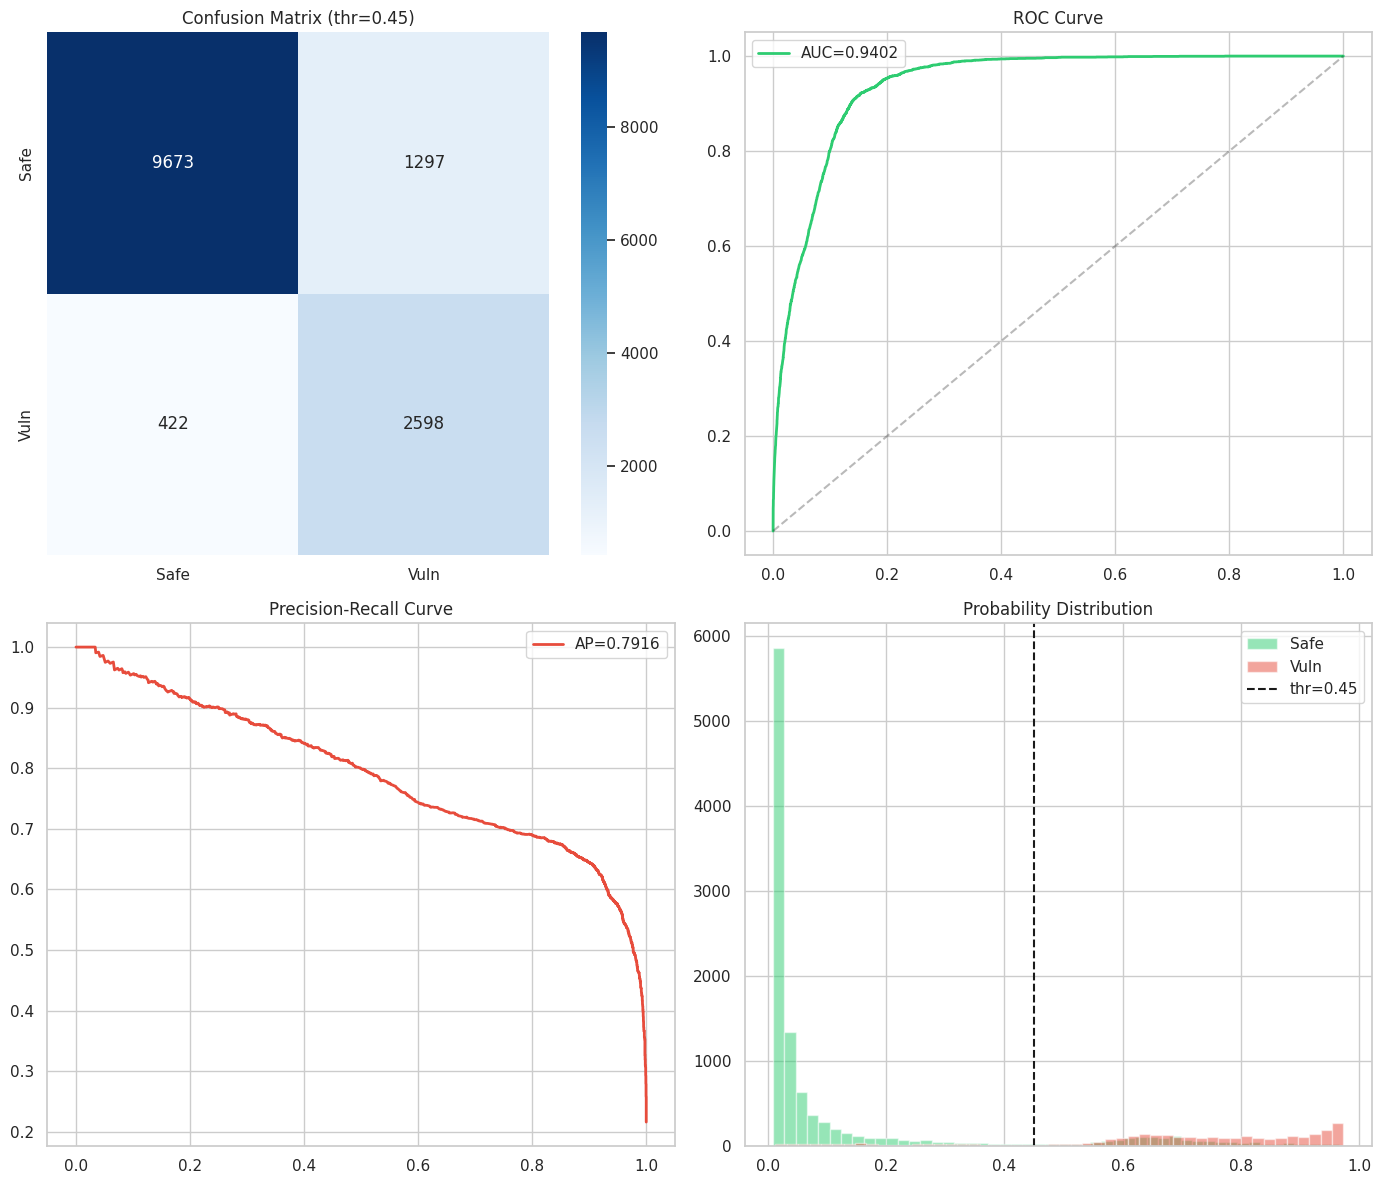

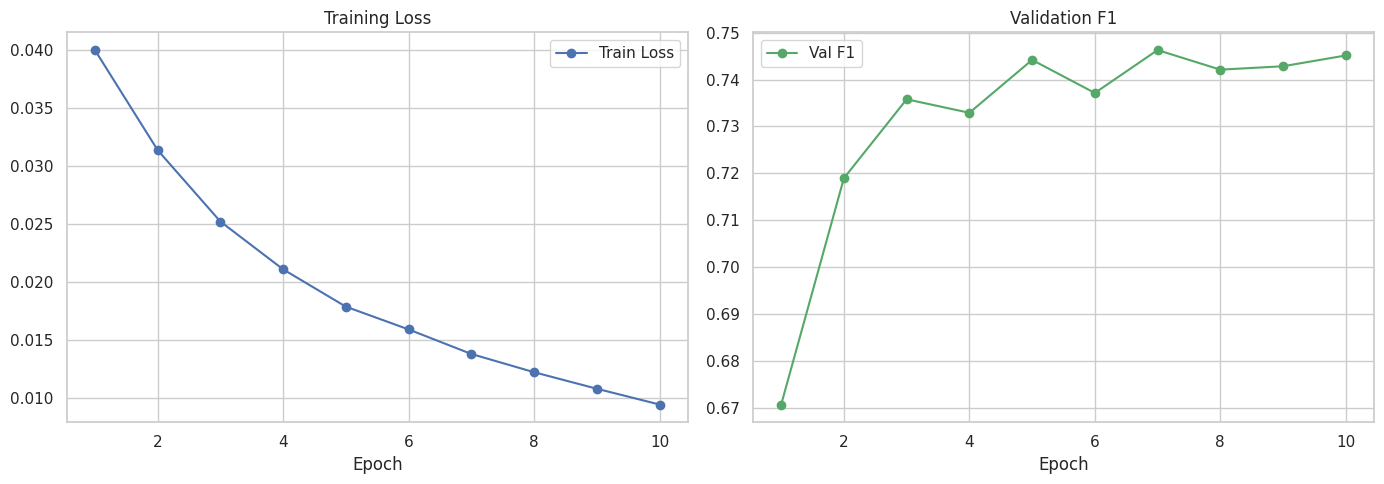

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# Confusion Matrix
cm = confusion_matrix(test_y, test_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0, 0],
            xticklabels=["Safe", "Vuln"], yticklabels=["Safe", "Vuln"])
axes[0, 0].set_title(f"Confusion Matrix (thr={best_threshold:.2f})")

# ROC Curve
if len(np.unique(test_y)) > 1:
    fpr, tpr, _ = roc_curve(test_y, test_prob)
    axes[0, 1].plot(fpr, tpr, label=f"AUC={roc_auc_score(test_y, test_prob):.4f}",
                    color="#2ecc71", lw=2)
    axes[0, 1].plot([0, 1], [0, 1], "k--", alpha=0.3)
    axes[0, 1].legend()
    axes[0, 1].set_title("ROC Curve")

# Precision-Recall Curve
p, r, _ = precision_recall_curve(test_y, test_prob)
axes[1, 0].plot(r, p, label=f"AP={average_precision_score(test_y, test_prob):.4f}",
                color="#e74c3c", lw=2)
axes[1, 0].legend()
axes[1, 0].set_title("Precision-Recall Curve")

# Probability Distribution
axes[1, 1].hist(test_prob[test_y == 0], bins=50, alpha=0.5, label="Safe", color="#2ecc71")
axes[1, 1].hist(test_prob[test_y == 1], bins=50, alpha=0.5, label="Vuln", color="#e74c3c")
axes[1, 1].axvline(best_threshold, color="k", linestyle="--", label=f"thr={best_threshold:.2f}")
axes[1, 1].legend()
axes[1, 1].set_title("Probability Distribution")

plt.tight_layout()
plt.savefig(CKPT_DIR / "diagnostics.png", dpi=120)
plt.show()

# Training History
if history:
    fig2, ax2 = plt.subplots(1, 2, figsize=(14, 5))
    epochs_done = [h["epoch"] for h in history]
    ax2[0].plot(epochs_done, [h["train_loss"] for h in history], "b-o", label="Train Loss")
    ax2[0].set_title("Training Loss")
    ax2[0].set_xlabel("Epoch")
    ax2[0].legend()
    ax2[1].plot(epochs_done, [h["val_f1"] for h in history], "g-o", label="Val F1")
    ax2[1].set_title("Validation F1")
    ax2[1].set_xlabel("Epoch")
    ax2[1].legend()
    plt.tight_layout()
    plt.savefig(CKPT_DIR / "training_history.png", dpi=120)
    plt.show()

## 10. Lưu kết quả và Summary

In [17]:
summary_path = CKPT_DIR / "summary.json"
summary_path.write_text(json.dumps({
    "mode": MODE,
    "best_val_f1": best_f1,
    "best_threshold": best_threshold,
    "test_metrics": test_metrics_result.to_dict(),
    "hyperparameters": {
        "batch_size": BATCH_SIZE,
        "grad_accum": GRAD_ACCUM,
        "epochs_trained": len(history),
        "lr_backbone": LR_BACKBONE,
        "lr_head": LR_HEAD,
        "focal_alpha": FOCAL_ALPHA,
        "focal_gamma": FOCAL_GAMMA,
        "patience": PATIENCE,
        "warmup_ratio": WARMUP_RATIO,
        "pad_to_multiple_of": 8,
        "fused_adamw": use_fused_adamw,
    },
    "history": history,
}, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"\n✅ Saved summary to {summary_path}")
print(f"\n🎉 Hoàn thành! Best Val F1={best_f1:.4f} @ thr={best_threshold:.2f}")
print("Đừng quên Save Version trên Kaggle.")


✅ Saved summary to /kaggle/working/models/checkpoints/semantic/summary.json

🎉 Hoàn thành! Best Val F1=0.7463 @ thr=0.45
Đừng quên Save Version trên Kaggle.


In [19]:
# Tạo dataframe chứa kết quả dự đoán trên tập test
import pandas as pd

test_results = pd.DataFrame({
    'sample_id': [s["sample_id"] for s in test_loader.dataset],
    'true_label': test_y,
    'prediction': test_pred,
    'probability': test_prob
})

csv_path = CKPT_DIR / "test_predictions.csv"
test_results.to_csv(csv_path, index=False)
print(f"✅ Đã lưu kết quả dự đoán chi tiết tại: {csv_path}")


✅ Đã lưu kết quả dự đoán chi tiết tại: /kaggle/working/models/checkpoints/semantic/test_predictions.csv


In [21]:
# (Tùy chọn) Nén và tải kết quả xuống
if IS_KAGGLE:
    import shutil
    from IPython.display import FileLink, display

    output_filename = '/kaggle/working/semantic_codebert_results'
    shutil.make_archive(
        base_name=output_filename,
        format='zip',
        root_dir=str(CKPT_DIR.parent.parent),
        base_dir='checkpoints',
    )
    display(FileLink(output_filename + '.zip'))

/kaggle/working/semantic_codebert_results.zip